A shopper buys either Pepsi or Coke each month, and which one depends only on what they bought
last month. That is a Markov chain with two states. This page works through one such chain: where
the market goes in a few months, where it settles, how long it takes to switch brands, what changes
when time runs continuously, and how an agent can learn to act on a chain it cannot see.

To run it yourself: `pip install numpy pandas matplotlib scipy`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.linalg import expm, logm

rng = np.random.default_rng(2020)

## The transition matrix

Row $i$ holds the probabilities of next month's purchase given this month's purchase $i$. A Pepsi
buyer stays with Pepsi with probability 0.7; a Coke buyer stays with Coke with probability 0.9. Each
row must sum to 1.

In [2]:
states = ["Pepsi", "Coke"]
P = np.array([[0.7, 0.3],
              [0.1, 0.9]])
print(pd.DataFrame(P, index=states, columns=states))
print("row sums:", P.sum(axis=1))

       Pepsi  Coke
Pepsi    0.7   0.3
Coke     0.1   0.9
row sums: [1. 1.]


## Where the market goes

Today Pepsi has 55% of the market and Coke 45%. Next month's shares are today's row vector times
$P$. **Predict:** does Pepsi's share go up or down after one month?

In [3]:
share = np.array([0.55, 0.45])
print("after 1 month:", share @ P)

after 1 month: [0.43 0.57]


Two months is $P$ applied twice, so the two-step matrix is $P^2$. In general the $n$-step
probabilities are $P^{(n)} = P^n$ (the Chapman-Kolmogorov equations):

$$p_{ij}^{(m+n)} = \sum_k p_{ik}^{(m)}\, p_{kj}^{(n)}$$

In [4]:
for n in (1, 2, 5):
    print(f"after {n} months:", (share @ np.linalg.matrix_power(P, n)).round(4))

after 1 months: [0.43 0.57]
after 2 months: [0.358 0.642]
after 5 months: [0.2733 0.7267]


The same calculation month by month for two years, starting once from today's market and once from
a market that is all Pepsi.

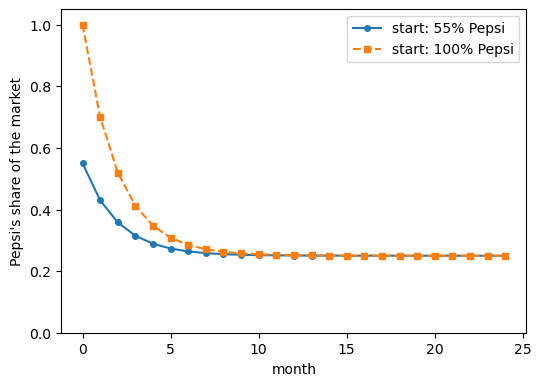

Pepsi share at month 24: 0.25 and 0.25


In [5]:
months = np.arange(25)
from_today = np.array([share @ np.linalg.matrix_power(P, n) for n in months])
from_pepsi = np.array([np.array([1.0, 0.0]) @ np.linalg.matrix_power(P, n) for n in months])
fig, ax = plt.subplots(figsize=(6, 4.2))
ax.plot(months, from_today[:, 0], "o-", markersize=4, label="start: 55% Pepsi")
ax.plot(months, from_pepsi[:, 0], "s--", markersize=4, label="start: 100% Pepsi")
ax.set(xlabel="month", ylabel="Pepsi's share of the market", ylim=(0, 1.05))
ax.legend()
plt.show()
print("Pepsi share at month 24:", from_today[24, 0].round(4), "and", from_pepsi[24, 0].round(4))
# alt: Pepsi's share falls from 0.55 (circles) and from 1.0 (squares) and both curves flatten onto the same value, 0.25, within about ten months.

## The steady state, solved by hand

If the shares stop changing, they satisfy $\pi = \pi P$ and $\pi_P + \pi_C = 1$. Written out:

$$\begin{aligned}
\pi_P &= 0.7\,\pi_P + 0.1\,\pi_C \\
\pi_C &= 0.3\,\pi_P + 0.9\,\pi_C \\
1 &= \pi_P + \pi_C
\end{aligned}$$

The first two equations say the same thing ($0.3\,\pi_P = 0.1\,\pi_C$), so keep one of them and the
normalising equation: two equations, two unknowns.

In [6]:
A = np.array([[-0.3, 0.1],    # -0.3 pi_P + 0.1 pi_C = 0
              [ 1.0, 1.0]])   #      pi_P +     pi_C = 1
b = np.array([0.0, 1.0])
pi = np.linalg.solve(A, b)
print("steady state (Pepsi, Coke):", pi)

steady state (Pepsi, Coke): [0.25 0.75]


Check it another way. If the chain forgets where it started, every row of $P^n$ should approach
$\pi$ as $n$ grows. **Predict** the rows of $P^{50}$.

In [7]:
print(np.linalg.matrix_power(P, 50).round(6))

[[0.25 0.75]
 [0.25 0.75]]


## Mean first passage times, solved by hand

Let $t_C$ be the expected number of months until a Coke buyer first buys Pepsi. One month always
passes; with probability 0.1 they switch (and the wait is over), with probability 0.9 they are a Coke
buyer again and the wait starts afresh:

$$t_C = 1 + 0.1 \cdot 0 + 0.9\, t_C$$

The mean recurrence time $r_P$ (months for a Pepsi buyer to come back to Pepsi) uses the same idea:
one month passes, then either they are already back or they are a Coke buyer with $t_C$ to go.

$$r_P = 1 + 0.7 \cdot 0 + 0.3\, t_C$$

In [8]:
t_coke = 1 / (1 - 0.9)
r_pepsi = 1 + 0.3 * t_coke
print("t_C =", round(t_coke, 4), "| r_P =", round(r_pepsi, 4), "| 1 / pi_P =", round(1 / pi[0], 4))

t_C = 10.0 | r_P = 4.0 | 1 / pi_P = 4.0


Check $t_C$ by simulation: start 10,000 shoppers on Coke, step each one through the chain until they
buy Pepsi, and average the number of months. **Predict:** roughly what share of those shoppers
take longer than 20 months?

In [9]:
waits = []
for shopper in range(10_000):
    state, steps = 1, 0                     # 1 = Coke, 0 = Pepsi
    while state != 0:
        state = 0 if rng.random() < P[state, 0] else 1
        steps += 1
    waits.append(steps)
waits = np.array(waits)
print("mean wait:", waits.mean().round(3), "| longest:", waits.max(), "| share over 20 months:", (waits > 20).mean().round(3))

mean wait: 10.229 | longest: 89 | share over 20 months: 0.129


## Continuous-time Markov chains

In continuous time the chain does not move once a month; it waits an exponential time in each state,
then jumps. It is described by a generator matrix of rates. Take a molecule with a low-energy state
$\sigma$ and an excited state $\sigma^*$: it jumps up at rate 3 and falls back at rate 1. The diagonal
entries make each row sum to zero. (The generator is often called $Q$; here it is `G`, because $Q$ is
needed later.)

In [10]:
energy = ["sigma", "sigma_star"]
G = np.array([[-3.0,  3.0],
              [ 1.0, -1.0]])
print(pd.DataFrame(G, index=energy, columns=energy))
print("row sums:", G.sum(axis=1))

            sigma  sigma_star
sigma        -3.0         3.0
sigma_star    1.0        -1.0
row sums: [0. 0.]


The steady state now satisfies $\pi G = 0$ with $\pi_\sigma + \pi_{\sigma^*} = 1$. As before, one
balance equation, $-3\pi_\sigma + \pi_{\sigma^*} = 0$, plus the normalising one.

In [11]:
pi_ct = np.linalg.solve(np.array([[-3.0, 1.0], [1.0, 1.0]]), np.array([0.0, 1.0]))
print("steady state (sigma, sigma_star):", pi_ct)

steady state (sigma, sigma_star): [0.25 0.75]


The transition probabilities over a stretch of time $t$ are the matrix exponential
$P(t) = e^{Gt}$. Start 80% of the molecules in $\sigma$. **Predict:** by $t = 4$, how close is the
split to the steady state?

In [12]:
start = np.array([0.8, 0.2])
for t in (0.25, 0.5, 1, 2, 4):
    print(f"t = {t:4}: (sigma, sigma_star) =", (start @ expm(G * t)).round(4))

t = 0.25: (sigma, sigma_star) = [0.4523 0.5477]
t =  0.5: (sigma, sigma_star) = [0.3244 0.6756]
t =    1: (sigma, sigma_star) = [0.2601 0.7399]
t =    2: (sigma, sigma_star) = [0.2502 0.7498]
t =    4: (sigma, sigma_star) = [0.25 0.75]


One molecule's path up to $t = 4$: draw the starting state from $(0.8, 0.2)$, hold for an
exponential time with rate $-G_{ii}$, jump to the other state, repeat.

In [13]:
state = rng.choice(2, p=start)
t, path = 0.0, []
while True:
    hold = rng.exponential(1 / -G[state, state])
    if t + hold > 4:
        break
    t += hold
    state = 1 - state
    path.append((round(t, 3), energy[state]))
print("jumps (time, new state):", path)

jumps (time, new state): [(0.249, 'sigma_star'), (3.712, 'sigma'), (3.815, 'sigma_star')]


Going the other way: which continuous-time chain, looked at once a month, gives the Coke and Pepsi
matrix? Its generator is the matrix logarithm of $P$. Check that the off-diagonal entries are
positive rates and the rows sum to zero, and that $e^{G}$ gives back $P$.

In [14]:
G_cola = logm(P).real
print("generator:\n", pd.DataFrame(G_cola.round(4), index=states, columns=states))
print("expm(generator):\n", expm(G_cola).round(4))

generator:
         Pepsi    Coke
Pepsi -0.3831  0.3831
Coke   0.1277 -0.1277
expm(generator):
 [[0.7 0.3]
 [0.1 0.9]]


## Learning to act on a chain: Q-learning

Now let Pepsi choose an action each month: advertise or not. Advertising costs \$0.30 per shopper
and changes the chain; each month the shopper buys Pepsi, Pepsi earns \$1. Future months count
less, by a factor $\gamma = 0.9$ per month.

In [15]:
P_by_action = {0: P,                                 # 0 = no advert
               1: np.array([[0.8, 0.2],              # 1 = advert
                            [0.3, 0.7]])}
cost, gamma = 0.3, 0.9
print("advert raises P(Pepsi next) from", P[:, 0], "to", P_by_action[1][:, 0])

advert raises P(Pepsi next) from [0.7 0.1] to [0.8 0.3]


Because the chain is known, the value of each (state, action) pair can be computed exactly by
repeating the Bellman equation until it stops changing. The first line is this month's expected
reward; the second is the discounted value of where the shopper goes next.

$$\begin{aligned}
Q(s, a) = {} & p_{s,\text{Pepsi}}(a) - 0.3\,a \\
& + \gamma \sum_{s'} p_{ss'}(a) \max_{a'} Q(s', a')
\end{aligned}$$

In [16]:
Q_exact = np.zeros((2, 2))
for sweep in range(500):
    V = Q_exact.max(axis=1)
    for s in range(2):
        for a in range(2):
            Q_exact[s, a] = P_by_action[a][s, 0] - cost * a + gamma * P_by_action[a][s] @ V
print(pd.DataFrame(Q_exact.round(3), index=["now Pepsi", "now Coke"], columns=["no advert", "advert"]))

           no advert  advert
now Pepsi      4.047   3.945
now Coke       2.856   2.953


Q-learning gets the same table without knowing the matrices. It watches one shopper, picks an action
at random each month, sees the reward $r$ and the next state $s'$, and nudges one entry:

$$Q(s, a) \leftarrow Q(s, a) + \alpha \big[\, r + \gamma \max_{a'} Q(s', a') - Q(s, a) \,\big]$$

The matrices appear in the loop below only to play the shopper; the update never reads them.
**Predict:** after 50,000 months, will the learned table pick the same action in each state as the
exact one?

In [17]:
Q = np.zeros((2, 2))
alpha, s = 0.01, 1
for month in range(50_000):
    a = rng.integers(2)
    s_next = 0 if rng.random() < P_by_action[a][s, 0] else 1
    r = (1.0 if s_next == 0 else 0.0) - cost * a
    Q[s, a] += alpha * (r + gamma * Q[s_next].max() - Q[s, a])
    s = s_next
print(pd.DataFrame(Q.round(3), index=["now Pepsi", "now Coke"], columns=["no advert", "advert"]))
print("learned policy:", [["no advert", "advert"][k] for k in Q.argmax(axis=1)])
print("exact policy:  ", [["no advert", "advert"][k] for k in Q_exact.argmax(axis=1)])

           no advert  advert
now Pepsi      4.050   3.958
now Coke       2.817   2.852
learned policy: ['no advert', 'advert']
exact policy:   ['no advert', 'advert']


Markov chains are one family of stochastic processes. Two others worth meeting next are martingales
(the running total of a fair game) and Bayesian networks (random variables linked by conditional
probabilities).

## Questions

- The steady state does not depend on the starting shares. Which property of $P$ would have to fail
  for that to stop being true?
- Lower the advert's cost from \$0.30 to \$0.10 and rerun the last three cells. Which state's
  decision changes, and does Q-learning notice?
- The learned table is close to the exact one but not equal. What would you change in the Q-learning
  loop to bring it closer, and what would that cost?